# Offline index research — bundled real market data

QuantLab ships daily OHLCV history for 8 major indices (S&P 500 back to **1927**),
downloaded once via `download_data.py` and loaded here with **zero network**.

Ask the AI mentor (`e` on any cell) about cross-index momentum, vol regimes, or the VIX.

In [6]:
from quantlab_data import available, load_index, closes

for key, desc in available().items():
    print(f"{key:<13} {desc}")

dax           DAX (1987-12-30 → 2026-07-17, 9747 rows)
dow           Dow Jones Industrial Average (1992-01-02 → 2026-07-16, 8695 rows)
ftse100       FTSE 100 (1984-01-03 → 2026-07-17, 10746 rows)
nasdaq        NASDAQ Composite (1971-02-05 → 2026-07-16, 13977 rows)
nikkei225     Nikkei 225 (1965-01-05 → 2026-07-17, 15128 rows)
russell2000   Russell 2000 (1987-09-10 → 2026-07-16, 9785 rows)
sp500         S&P 500 (1927-12-30 → 2026-07-16, 24751 rows)
vix           CBOE Volatility Index (1990-01-02 → 2026-07-17, 9203 rows)


In [7]:
spx = load_index("sp500", start="1990-01-01")
spx.tail()

,Close,High,Low,Open,Volume
Date,,,,,
2026-07-10,7575.390137,7579.930176,7508.160156,7547.640137,4006370000
2026-07-13,7515.339844,7565.370117,7506.410156,7547.529785,4729990000
2026-07-14,7543.589844,7557.439941,7513.229980,7536.700195,4836950000
2026-07-15,7572.399902,7581.500000,7526.950195,7571.720215,5236550000
2026-07-16,7533.770020,7570.740234,7504.020020,7558.799805,5365300000


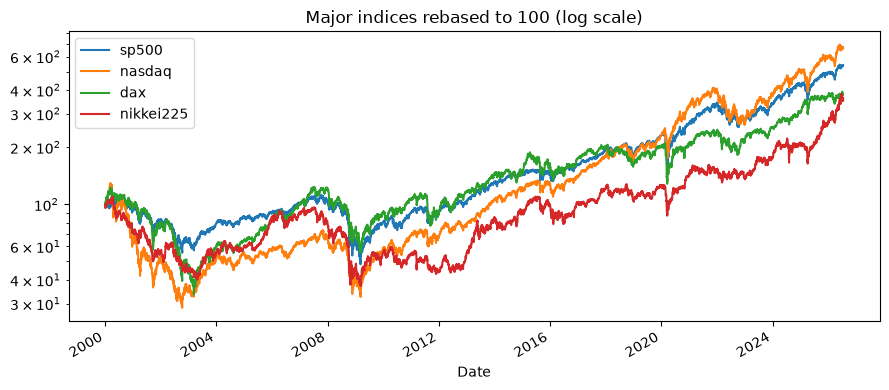

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Cross-index comparison since 2000, rebased to 100
px = closes("sp500", "nasdaq", "dax", "nikkei225", start="2000-01-01").dropna()
rebased = 100 * px / px.iloc[0]
rebased.plot(figsize=(9, 4), logy=True, title="Major indices rebased to 100 (log scale)")
plt.tight_layout(); plt.show()

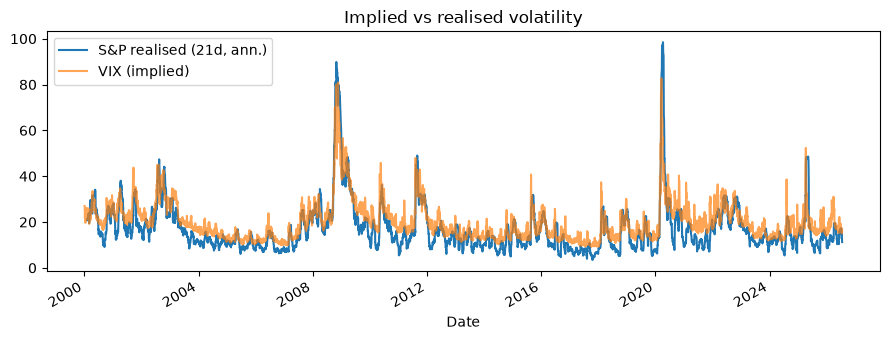

corr(VIX today, realised vol 1m later) = 0.71  — implied vol is forward-looking


In [9]:
# Realised volatility vs the VIX — does implied vol lead realised?
vix = load_index("vix", start="2000-01-01")["Close"]
spx_ret = px["sp500"].pct_change()
realised = spx_ret.rolling(21).std() * np.sqrt(252) * 100  # 1-month realised, in vol points

pd_ax = realised.plot(figsize=(9, 3.5), label="S&P realised (21d, ann.)")
vix.reindex(realised.index).plot(ax=pd_ax, alpha=0.7, label="VIX (implied)")
pd_ax.legend(); pd_ax.set_title("Implied vs realised volatility")
plt.tight_layout(); plt.show()

corr = realised.corr(vix.reindex(realised.index).shift(21))
print(f"corr(VIX today, realised vol 1m later) = {corr:.2f}  — implied vol is forward-looking")

TSMOM basket   sharpe= 0.65  maxDD=-24.69%
Buy&hold basket sharpe= 0.62  maxDD=-54.19%


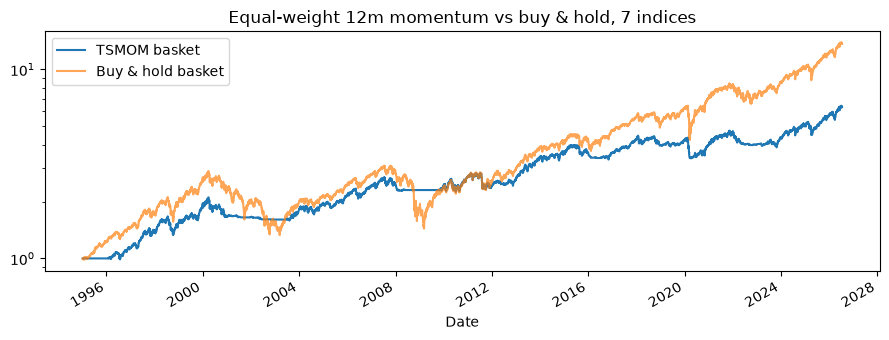

In [10]:
# 12-month time-series momentum across all equity indices (vectorised, no look-ahead)
eq = closes("sp500", "nasdaq", "dow", "russell2000", "ftse100", "dax", "nikkei225",
            start="1995-01-01").dropna()
rets = eq.pct_change()
signal = (eq.pct_change(252) > 0).astype(float).shift(1)   # trade the day AFTER the signal
tsmom = (signal * rets).mean(axis=1)                        # equal-weight across indices

def sharpe(r): return np.sqrt(252) * r.mean() / r.std()
def max_dd(r):
    eqty = (1 + r).cumprod()
    return (eqty / eqty.cummax() - 1).min()

bench = rets.mean(axis=1)
print(f"TSMOM basket   sharpe={sharpe(tsmom.dropna()):5.2f}  maxDD={max_dd(tsmom.dropna()):7.2%}")
print(f"Buy&hold basket sharpe={sharpe(bench.dropna()):5.2f}  maxDD={max_dd(bench.dropna()):7.2%}")

(1 + tsmom.dropna()).cumprod().plot(figsize=(9, 3.5), label="TSMOM basket", logy=True)
(1 + bench.dropna()).cumprod().plot(label="Buy & hold basket", alpha=0.7)
plt.legend(); plt.title("Equal-weight 12m momentum vs buy & hold, 7 indices")
plt.tight_layout(); plt.show()

## Refreshing the data

The bundle is a snapshot. To pull the latest bars (network needed):

```bash
.venv/bin/python download_data.py            # everything
.venv/bin/python download_data.py sp500 vix  # subset
```